In [55]:
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

In [2]:
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s"
)

logger = logging.getLogger(__name__)

In [5]:
df = pd.read_csv("train.csv")

logger.info("Dataset loaded successfully.")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
print(df.head())

2026-09-23 23:28:48,749 - INFO - Dataset loaded successfully.



Dataset Shape:
(1460, 81)

First 5 Rows:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCo

In [7]:
print("\n------------------------------")
print("BASIC DATA INFORMATION")
print("------------------------------")

print("\nNumber of rows:")
print(df.shape[0])

print("\nNumber of columns:")
print(df.shape[1])

print("\nColumn data types:")
print(df.dtypes.value_counts())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nMissing SalePrice values:")
print(df["SalePrice"].isna().sum())



------------------------------
BASIC DATA INFORMATION
------------------------------

Number of rows:
1460

Number of columns:
81

Column data types:
object     43
int64      35
float64     3
Name: count, dtype: int64

Duplicate rows:
0

Missing SalePrice values:
0


In [9]:
print("\n------------------------------")
print("SALE PRICE STATISTICS")
print("------------------------------")

print(df["SalePrice"].describe())

print("\nSalePrice Skewness:")
print(df["SalePrice"].skew())



------------------------------
SALE PRICE STATISTICS
------------------------------
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

SalePrice Skewness:
1.8828757597682129


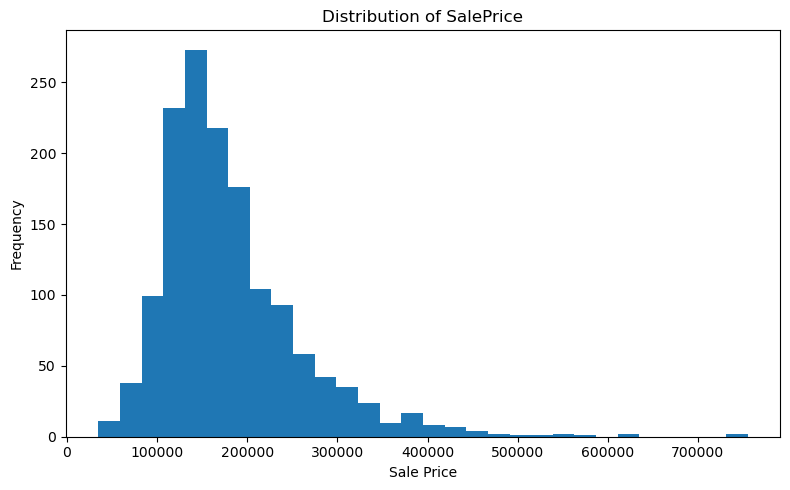

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["SalePrice"],
    bins=30
)

plt.title("Distribution of SalePrice")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [13]:
missing_values = df.isna().sum()

missing_values = missing_values[
    missing_values > 0
]

missing_values = missing_values.sort_values(
    ascending=False
)


missing_table = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage":
        (missing_values / len(df) * 100).round(2)
})


print("\n------------------------------")
print("TOP MISSING VALUE COLUMNS")
print("------------------------------")

print(missing_table.head(15))


------------------------------
TOP MISSING VALUE COLUMNS
------------------------------
              Missing Count  Missing Percentage
PoolQC                 1453               99.52
MiscFeature            1406               96.30
Alley                  1369               93.77
Fence                  1179               80.75
MasVnrType              872               59.73
FireplaceQu             690               47.26
LotFrontage             259               17.74
GarageType               81                5.55
GarageYrBlt              81                5.55
GarageFinish             81                5.55
GarageQual               81                5.55
GarageCond               81                5.55
BsmtFinType2             38                2.60
BsmtExposure             38                2.60
BsmtFinType1             37                2.53


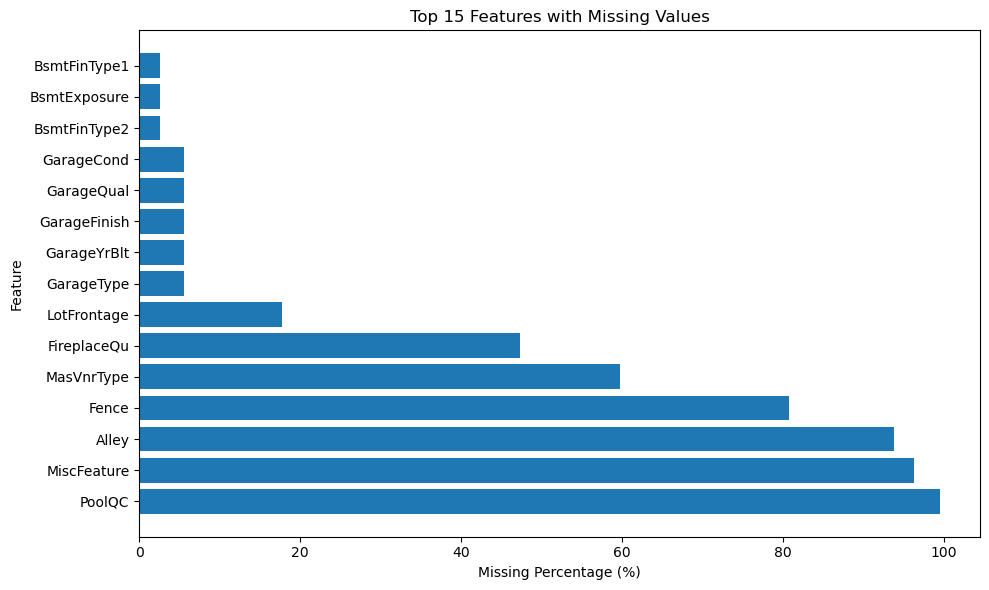

In [15]:
top_missing = missing_table.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_missing.index,
    top_missing["Missing Percentage"]
)

plt.title("Top 15 Features with Missing Values")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [17]:
numeric_df = df.select_dtypes(
    include=np.number
)


correlations = numeric_df.corr()["SalePrice"]

correlations = correlations.drop(
    "SalePrice"
)

correlations = correlations.sort_values(
    key=lambda x: x.abs(),
    ascending=False
)


print("\n------------------------------")
print("TOP CORRELATIONS WITH SALEPRICE")
print("------------------------------")

print(correlations.head(15))



------------------------------
TOP CORRELATIONS WITH SALEPRICE
------------------------------
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.351799
Name: SalePrice, dtype: float64


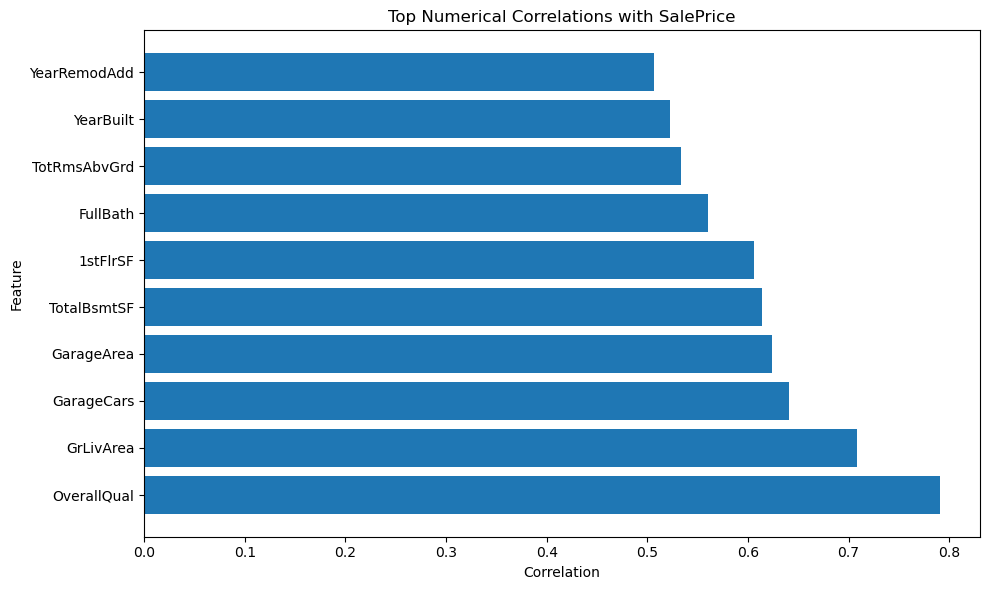

In [19]:
top_correlations = correlations.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_correlations.index,
    top_correlations.values
)

plt.title("Top Numerical Correlations with SalePrice")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


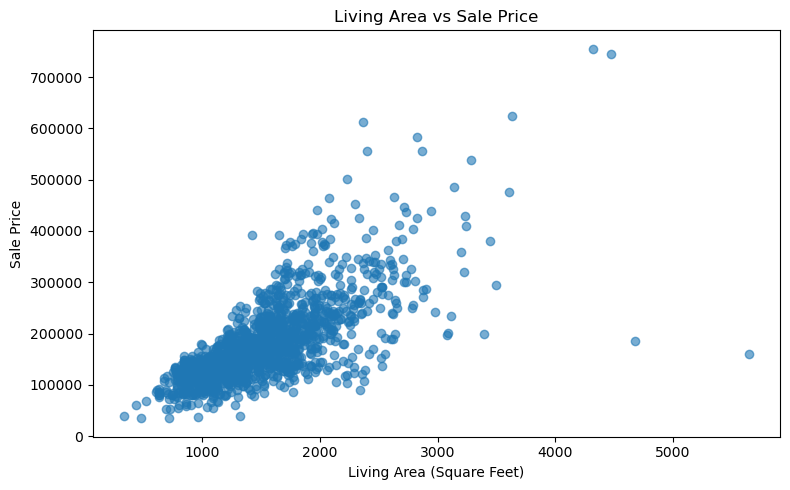

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["GrLivArea"],
    df["SalePrice"],
    alpha=0.6
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price")

plt.tight_layout()
plt.show()

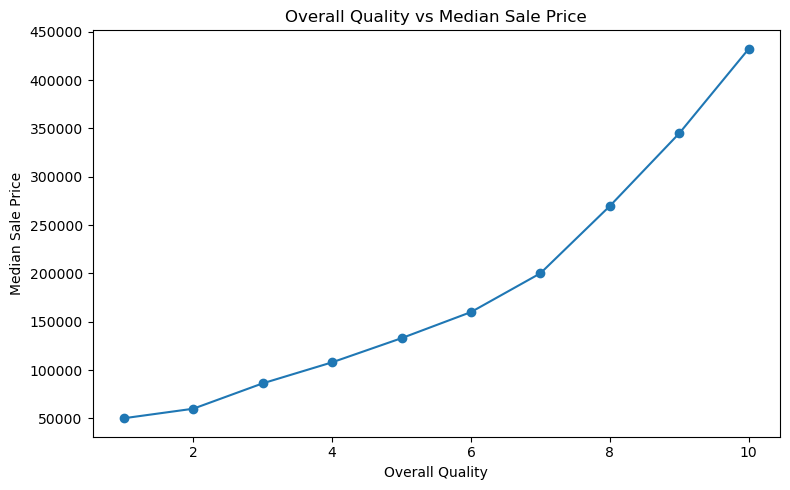

In [23]:
quality_price = df.groupby(
    "OverallQual"
)["SalePrice"].median()


plt.figure(figsize=(8, 5))

plt.plot(
    quality_price.index,
    quality_price.values,
    marker="o"
)

plt.title("Overall Quality vs Median Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Median Sale Price")

plt.tight_layout()
plt.show()

In [25]:
X = df.drop(
    columns=[
        "SalePrice",
        "Id"
    ]
)

y = df["SalePrice"]


print("\nFeature matrix shape:")
print(X.shape)

print("\nTarget shape:")
print(y.shape)


Feature matrix shape:
(1460, 79)

Target shape:
(1460,)


In [27]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()


categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()


print("\nNumber of Numerical Features:")
print(len(numerical_features))

print("\nNumber of Categorical Features:")
print(len(categorical_features))



Number of Numerical Features:
36

Number of Categorical Features:
43


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print("\nTraining Data:")
print(X_train.shape)

print("\nTesting Data:")
print(X_test.shape)


Training Data:
(1168, 79)

Testing Data:
(292, 79)


In [31]:
numerical_pipeline = Pipeline(
    steps=[

        (
            "mean_imputer",
            SimpleImputer(
                strategy="mean"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )

    ]
)

In [33]:
categorical_pipeline = Pipeline(
    steps=[

        (
            "missing_imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),

        (
            "one_hot_encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )

    ]
)

In [35]:
preprocessor = ColumnTransformer(
    transformers=[

        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),

        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )

    ]
)

In [37]:
model_pipeline = Pipeline(
    steps=[

        (
            "preprocessing",
            preprocessor
        ),

        (
            "ridge",
            Ridge()
        )

    ]
)

In [39]:
parameter_grid = {

    "ridge__alpha": [
        0.1,
        1,
        10,
        100,
        1000
    ]

}

In [41]:
grid_search = GridSearchCV(

    estimator=model_pipeline,

    param_grid=parameter_grid,

    cv=5,

    scoring="neg_root_mean_squared_error",

    n_jobs=-1
)

In [43]:
logger.info(
    "Starting Ridge Regression training..."
)

grid_search.fit(
    X_train,
    y_train
)

logger.info(
    "Training completed successfully."
)

2026-09-23 23:39:00,548 - INFO - Starting Ridge Regression training...
2026-09-23 23:39:03,822 - INFO - Training completed successfully.


In [45]:
best_model = grid_search.best_estimator_


print("\n------------------------------")
print("BEST MODEL")
print("------------------------------")

print(
    "Best Alpha:",
    grid_search.best_params_["ridge__alpha"]
)


print(
    "Best Cross Validation RMSE:",
    -grid_search.best_score_
)


------------------------------
BEST MODEL
------------------------------
Best Alpha: 10
Best Cross Validation RMSE: 32641.198387535587


In [47]:
y_pred = best_model.predict(
    X_test
)

In [49]:
r2 = r2_score(
    y_test,
    y_pred
)


mse = mean_squared_error(
    y_test,
    y_pred
)


rmse = np.sqrt(
    mse
)


mae = mean_absolute_error(
    y_test,
    y_pred
)


print("\n================================")
print("MODEL EVALUATION")
print("================================")

print(
    f"R² Score : {r2:.4f}"
)

print(
    f"RMSE     : ${rmse:,.2f}"
)

print(
    f"MAE      : ${mae:,.2f}"
)


logger.info(
    f"R² Score: {r2:.4f}"
)

logger.info(
    f"RMSE: {rmse:.2f}"
)


2026-09-23 23:40:19,923 - INFO - R² Score: 0.8785
2026-09-23 23:40:19,924 - INFO - RMSE: 30526.30



MODEL EVALUATION
R² Score : 0.8785
RMSE     : $30,526.30
MAE      : $19,178.67


In [51]:
results = pd.DataFrame({

    "Actual Price":
        y_test.values,

    "Predicted Price":
        y_pred

})


results["Error"] = (
    results["Actual Price"]
    -
    results["Predicted Price"]
)


print("\n------------------------------")
print("SAMPLE PREDICTIONS")
print("------------------------------")

print(
    results.head(10).round(2)
)


------------------------------
SAMPLE PREDICTIONS
------------------------------
   Actual Price  Predicted Price     Error
0        154500        160480.21  -5980.21
1        325000        336672.12 -11672.12
2        115000         97154.98  17845.02
3        159000        178907.88 -19907.88
4        315500        337878.90 -22378.90
5         75500         65046.04  10453.96
6        311500        247692.93  63807.07
7        146000        150290.27  -4290.27
8         84500         63951.06  20548.94
9        135500        149952.67 -14452.67


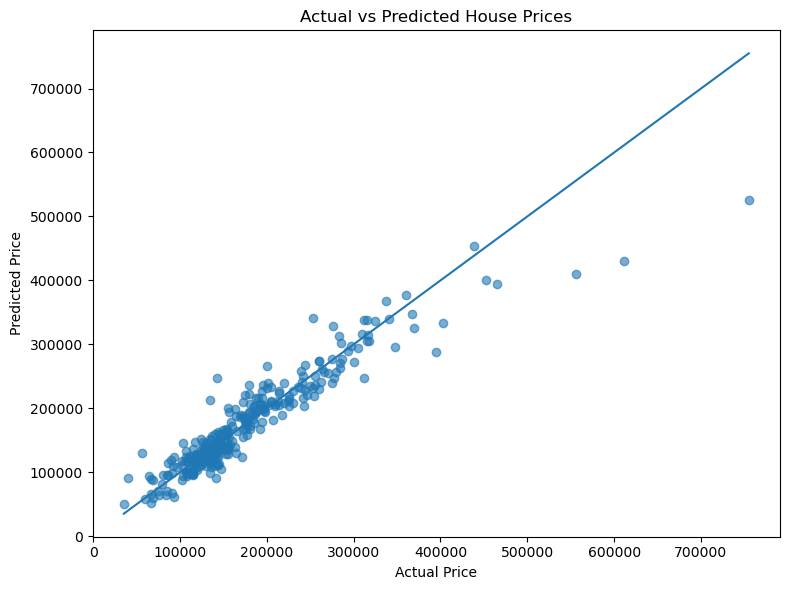

In [53]:
plt.figure(
    figsize=(8, 6)
)


plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)


minimum_value = min(
    y_test.min(),
    y_pred.min()
)


maximum_value = max(
    y_test.max(),
    y_pred.max()
)


plt.plot(
    [
        minimum_value,
        maximum_value
    ],

    [
        minimum_value,
        maximum_value
    ]
)


plt.title(
    "Actual vs Predicted House Prices"
)

plt.xlabel(
    "Actual Price"
)

plt.ylabel(
    "Predicted Price"
)

plt.tight_layout()

plt.show()

In [57]:
joblib.dump(
    best_model,
    "ridge_house_price_model.pkl"
)

print("Model saved successfully.")

Model saved successfully.
